In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random
import operator
import os

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
numvar = -1*10**22
newest_method_string = "{:6e}".format(numvar)
print(newest_method_string)

-1.000000e+22


In [3]:
#plt.rcParams['figure.facecolor'] = 'w'
#plt.rcParams['figure.edgecolor'] = 'k'

In [4]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data

In [5]:
def plot_x_y_data (xdata,ydata):
    plot.scatter(xdata,ydata,s=2)
    plot.show()
    plot.close()

In [6]:
# First, define function for ODR
def f10(B, x):
    '''Multi-Linear function y = B[0]*x0 + B[1]*x[1] + B[2]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x + B[1]
def do_odr_fit (data_to_fit):
    linear = Model(f10)
    logMdotData = np.log10(data_to_fit[5])
    logPData = np.log10(data_to_fit[13])
    logLData = np.log10(data_to_fit[8])
    mydata = Data(logPData,logMdotData)
    myodr = ODR(mydata,linear,beta0=[1,1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

In [7]:
def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


In [8]:
chi_sq_fit_2d (np.log10(M0StarData[PIndex]), np.log10(M0StarData[MdotIndex]))

(array([-9.12945005,  1.07245939]), 0.13555362512130098)

In [9]:
def calc_PE_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    potential_energy_scale = np.log10(Mass/Radius)
    return potential_energy_scale

def calc_g_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    g_scale = np.log10(Mass/Radius**2)
    return g_scale

def calc_lum_pressure_scale (stellar_data):
    Luminosity = stellar_data[LIndex]
    Radius = stellar_data[RIndex]
    L_Pressure_scale = np.log10(Luminosity/Radius**2)
    return L_Pressure_scale

def calc_core_lum_param (stellar_data):
    Luminosity = stellar_data[LIndex]
    Mass = stellar_data[MIndex]
    core_lum_param = np.log10(Luminosity/Mass)
    return core_lum_param

In [10]:
def plot_logmdot_vs_parameter (mdot, parameter, title='', parameter_label='',save_fig = 0, save_folder = '',testing = 0):
    plot.scatter(parameter,mdot,s=2,label='Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    if testing != 0:
        print('parameter:',parameter)
        print('np.min(parameter):',np.nanmin(parameter))
        print('np.max(parameter):',np.nanmax(parameter))
        print('fit_x:',fit_x)
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    if testing != 0:
        print('fit_y:',fit_x)
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [11]:
def plot_residual_vs_parameter (mdot_resid, parameter, title='', parameter_label='',save_fig = 0, save_folder = ''):
    plot.scatter(parameter,mdot_resid,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot_resid)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_calc-logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'Residuals/'+ 'residual_versus_'+ parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    return fit_parameters

In [12]:
def plot_logmdot_vs_logmdot (mdot, calc_mdot, title='',save_fig = 0, save_folder = ''):
    plot.scatter(mdot,calc_mdot,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (mdot, calc_mdot)
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.min([np.nanmin(mdot),np.nanmin(calc_mdot)]),np.nanmax([np.max(mdot),np.nanmax(calc_mdot)])])
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'logMdot_obsv'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(line_coords,line_coords,color='black', label = '1:1 Line')
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel('logMdot_obsv')
    plot.ylabel('logMdot_calc')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_calc_versus_logMdot_obsv' + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [13]:
def full_parameter_analysis (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot_logmdot_vs_parameter (stellar_data_mdot, stellar_data_x, title=plot_label, parameter_label=stellar_data_xlabel,save_folder = save_folder,save_fig = save_fig)
    #plot.scatter(stellar_data_x,stellar_data_mdot,s=2)
    #fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    #fit_y = Betas[0] + Betas[1]*fit_x
    #plot.plot(fit_x,fit_y,color='orange')
    #plot.xlabel(stellar_data_xlabel)
    #plot.ylabel('logMdot_obsv')
    #plot.title(plot_label)
    #plot.show()
    #plot.close()
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)

M0:

 Fit: logMdot= 1.0724593860158076 *x+ -9.129450050764325


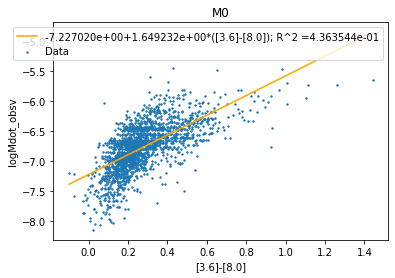

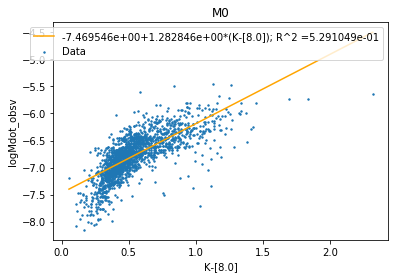


M1:

 Fit: logMdot= 1.6521814302947757 *x+ -10.11241020312467


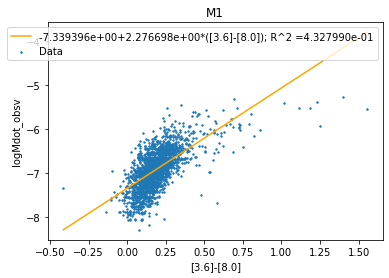

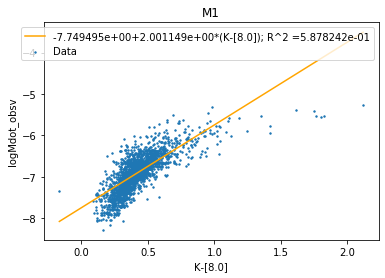


C0

 Fit: logMdot= 2.368635896953745 *x+ -12.463808359086066


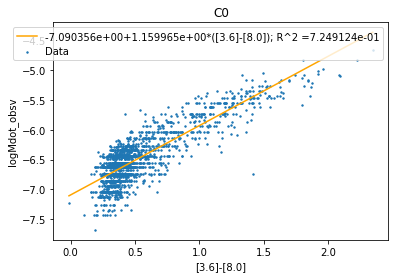

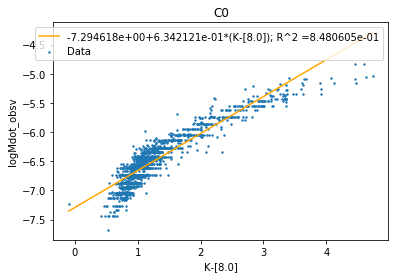


C1

 Fit: logMdot= 1.8727180628612656 *x+ -10.850658502379884


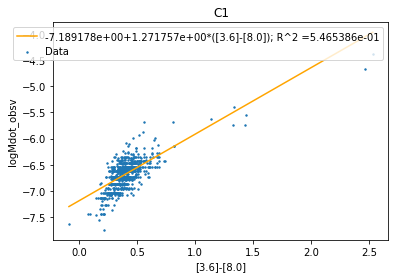

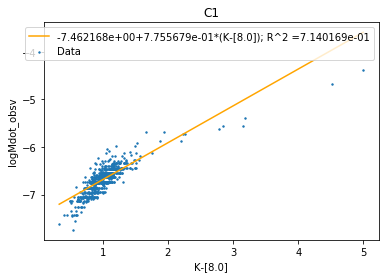

In [14]:
Directory = 'Single_Parameter_Fits/logP'
print('M0:')
full_parameter_analysis (np.log10(M0StarData[PIndex]), np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(P)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1StarData[PIndex]), np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(P)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0StarData[PIndex]), np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(P)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1StarData[PIndex]), np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(P)', plot_label='C1', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= 0.2853920569709354 *x+ -7.782489763523183


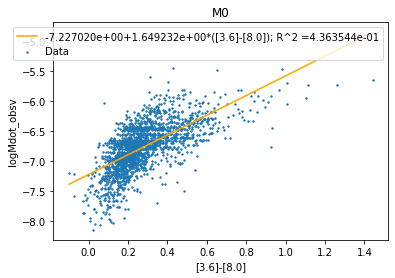

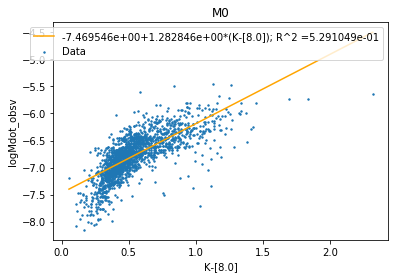


M1:

 Fit: logMdot= 0.9249016704715189 *x+ -10.215632571633746


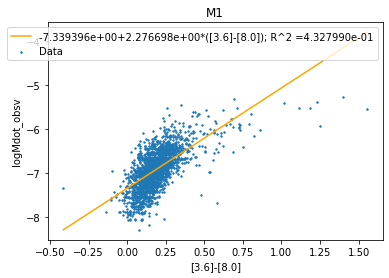

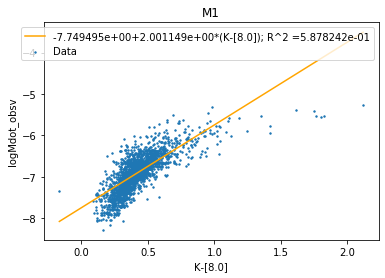


C0

 Fit: logMdot= 0.3056790977427254 *x+ -7.654858164570391


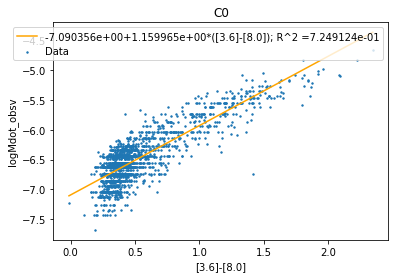

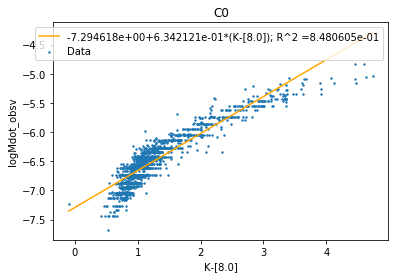


C1

 Fit: logMdot= 0.7515806670664427 *x+ -9.582140145373783


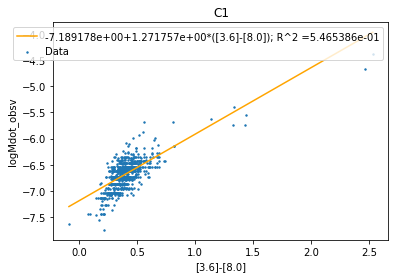

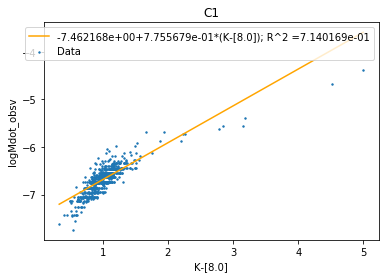

In [15]:
Directory = 'Single_Parameter_Fits/logL'
print('M0:')
full_parameter_analysis (np.log10(M0StarData[LIndex]), np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(L)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1StarData[LIndex]), np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(L)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0StarData[LIndex]), np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(L)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1StarData[LIndex]), np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(L)', plot_label='C1', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= 0.8506255311152886 *x+ -8.636860427983935


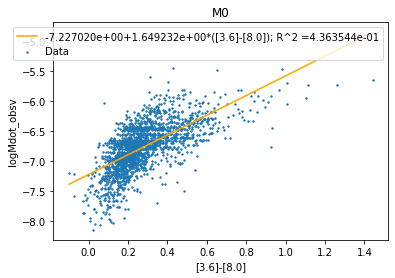

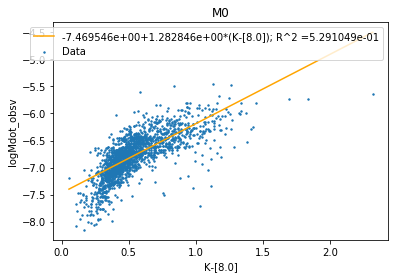


M1:

 Fit: logMdot= 1.757851213881129 *x+ -10.821039211879313


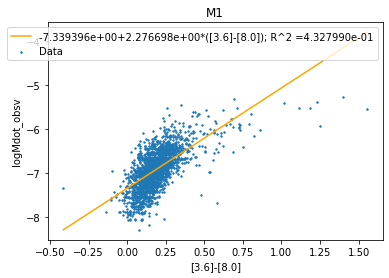

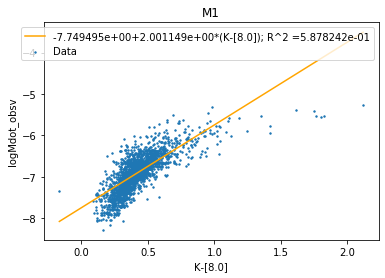


C0

 Fit: logMdot= 1.3810689623251582 *x+ -9.831937728615092


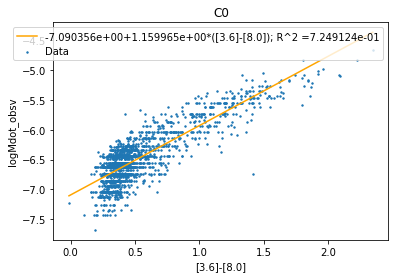

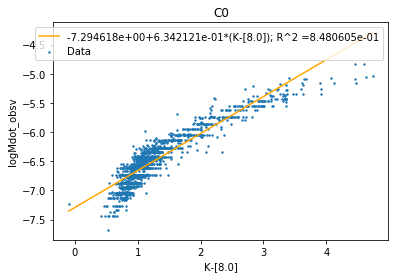


C1

 Fit: logMdot= 1.933929693619536 *x+ -11.444449080250408


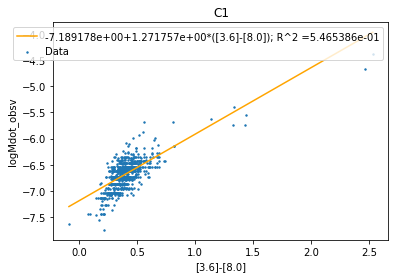

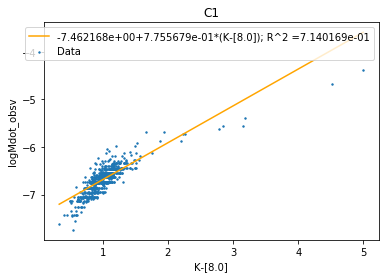

In [16]:
Directory = 'Single_Parameter_Fits/logR'
print('M0:')
full_parameter_analysis (np.log10(M0StarData[RIndex]), np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(R)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1StarData[RIndex]), np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(R)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0StarData[RIndex]), np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(R)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1StarData[RIndex]), np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(R)', plot_label='C1', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= -0.47036631694929026 *x+ -6.77007950579689


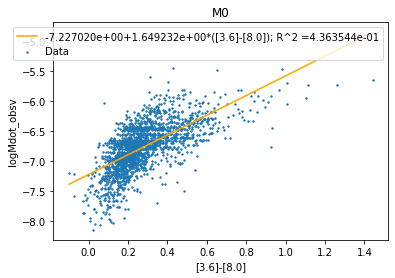

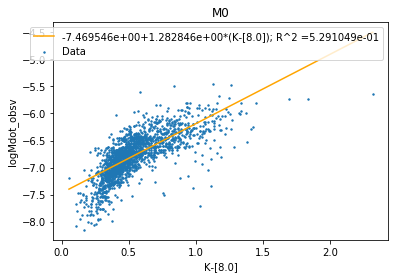


M1:

 Fit: logMdot= 0.837469975615651 *x+ -6.907433375044894


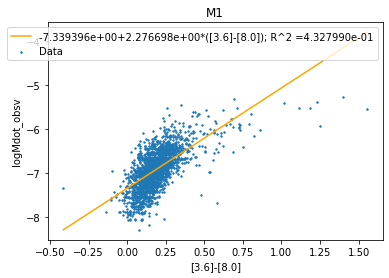

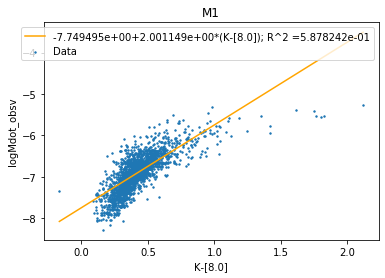


C0

 Fit: logMdot= -0.5206208257942018 *x+ -6.40466512601211


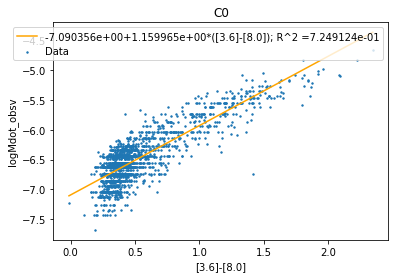

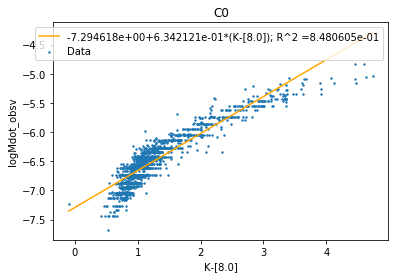


C1

 Fit: logMdot= 0.04067839642250537 *x+ -6.681820245464722


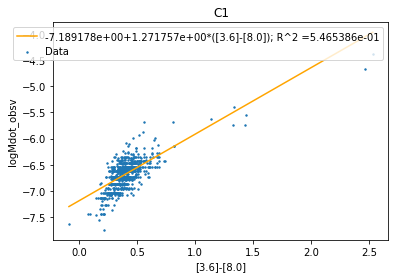

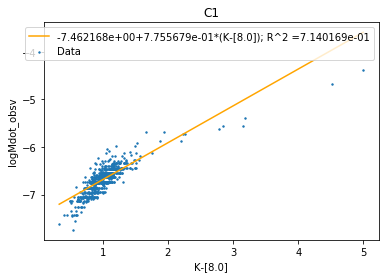

In [17]:
Directory = 'Single_Parameter_Fits/logM'
print('M0:')
full_parameter_analysis (np.log10(M0StarData[MIndex]), np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(M)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1StarData[MIndex]), np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(M)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0StarData[MIndex]), np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(M)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1StarData[MIndex]), np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(M)', plot_label='C1', save_fig = 1, save_folder=Directory)

In [18]:
M0_logPE = calc_PE_scale(M0StarData)
M1_logPE = calc_PE_scale(M1StarData)
C0_logPE = calc_PE_scale(C0StarData)
C1_logPE = calc_PE_scale(C1StarData)

M0_logg = calc_g_scale(M0StarData)
M1_logg = calc_g_scale(M1StarData)
C0_logg = calc_g_scale(C0StarData)
C1_logg = calc_g_scale(C1StarData)

M0_logLP = calc_lum_pressure_scale(M0StarData)
M1_logLP = calc_lum_pressure_scale(M1StarData)
C0_logLP = calc_lum_pressure_scale(C0StarData)
C1_logLP = calc_lum_pressure_scale(C1StarData)

M0_logCL = calc_core_lum_param(M0StarData)
M1_logCL = calc_core_lum_param(M1StarData)
C0_logCL = calc_core_lum_param(C0StarData)
C1_logCL = calc_core_lum_param(C1StarData)


 Fit: logMdot= -2.0140052683974288 *x+ -11.157663910225905


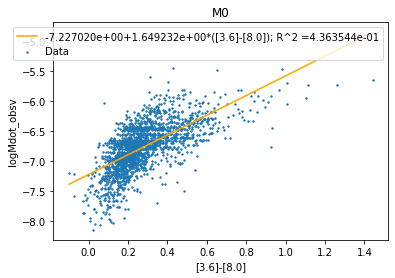

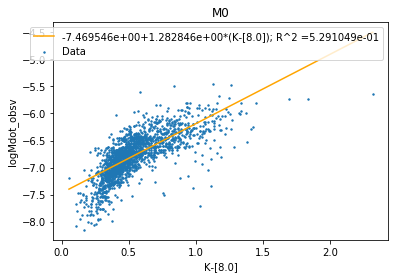


 Fit: logMdot= -2.445318885514026 *x+ -12.33832559829561


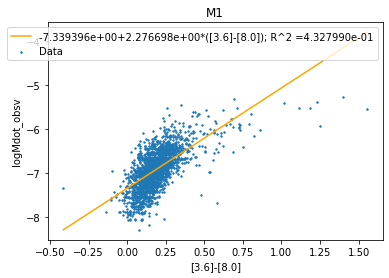

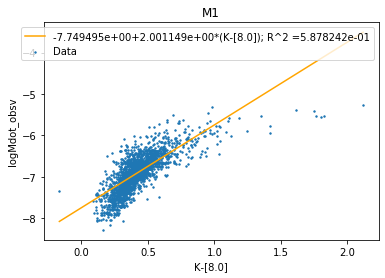


 Fit: logMdot= -2.9550717214226516 *x+ -13.142535968446216


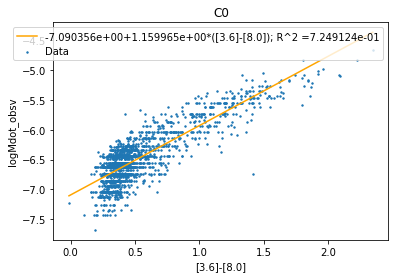

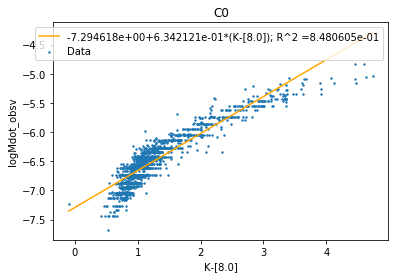


 Fit: logMdot= -1.4027187481992487 *x+ -9.901832968377517


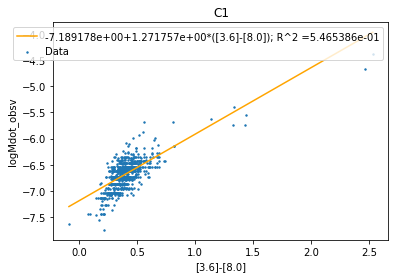

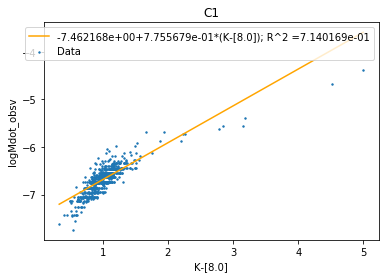

In [19]:
Directory = 'Single_Parameter_Fits/log(M/R)'
full_parameter_analysis (M0_logPE, np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logPE, np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logPE, np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logPE, np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(M/R)', plot_label='C1', save_fig = 1, save_folder=Directory)


 Fit: logMdot= -1.279001051526012 *x+ -12.356803542160005


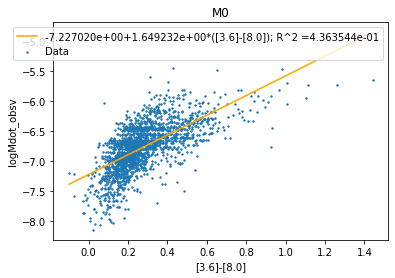

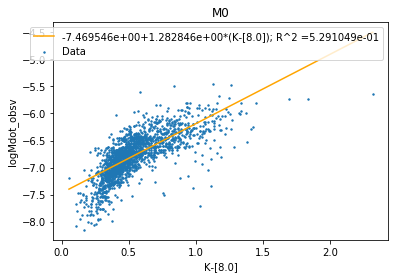


 Fit: logMdot= -1.5186769649261573 *x+ -13.663976900457588


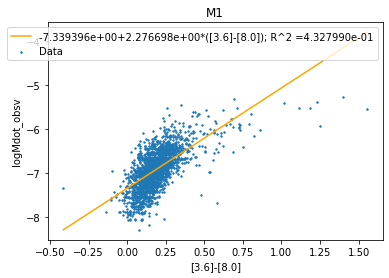

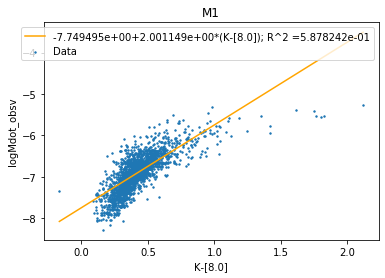


 Fit: logMdot= -2.8140508646811258 *x+ -19.630521118921074


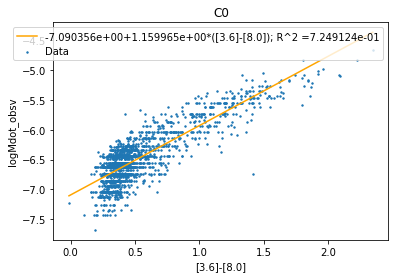

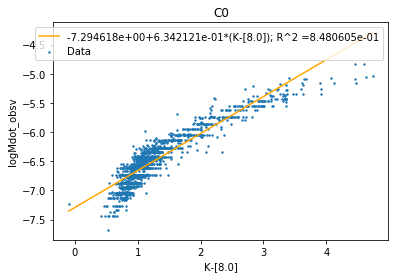


 Fit: logMdot= -1.4648923113006382 *x+ -13.657508130981059


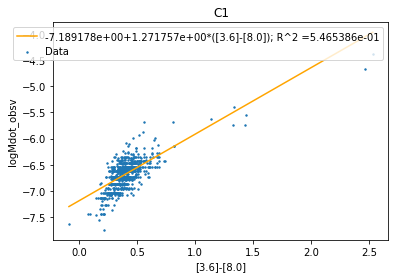

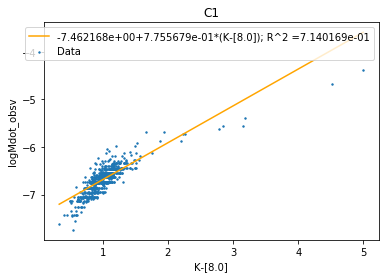

In [20]:
Directory = 'Single_Parameter_Fits/log(M/R^2)'
full_parameter_analysis (M0_logg, np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(M/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logg, np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(M/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logg, np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(M/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logg, np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(M/R^2)', plot_label='C1', save_fig = 1, save_folder=Directory)


 Fit: logMdot= -4.983880459427999 *x+ -11.0039258595151


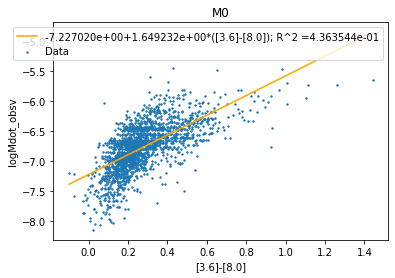

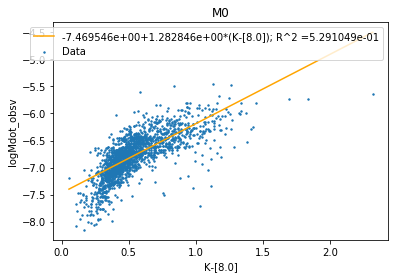


 Fit: logMdot= -5.967940554038217 *x+ -12.131301347385936


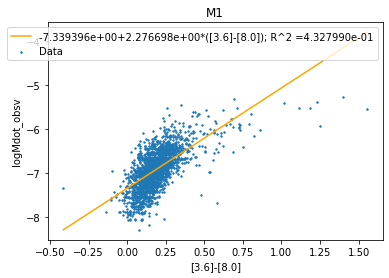

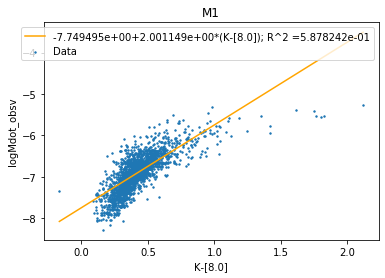


 Fit: logMdot= -7.158316954479842 *x+ -13.88384379076598


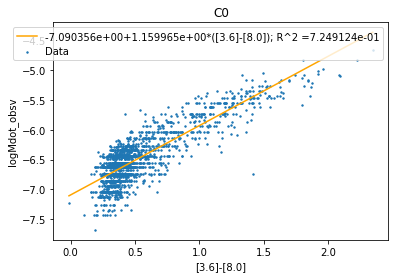

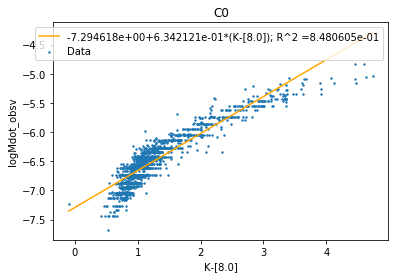


 Fit: logMdot= -3.227095083374283 *x+ -10.109928487163657


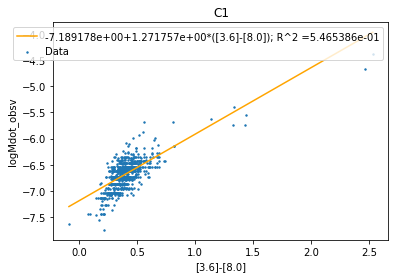

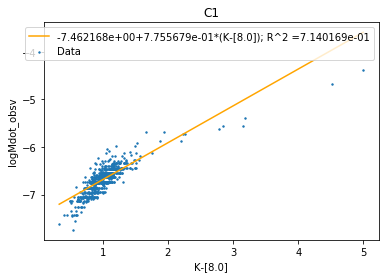

In [21]:
Directory = 'Single_Parameter_Fits/log(L/R^2)'
full_parameter_analysis (M0_logLP, np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(L/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logLP, np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(L/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logLP, np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(L/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logLP, np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(L/R^2)', plot_label='C1', save_fig = 1, save_folder=Directory)


 Fit: logMdot= 1.6353844089073903 *x+ -12.524510499135442


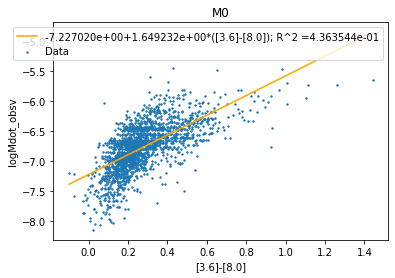

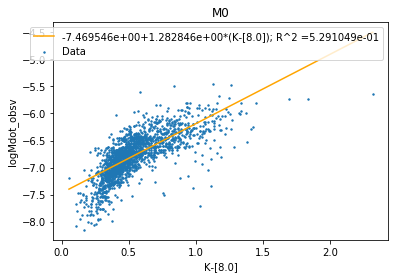


 Fit: logMdot= 1.9880293084246126 *x+ -14.011818495728669


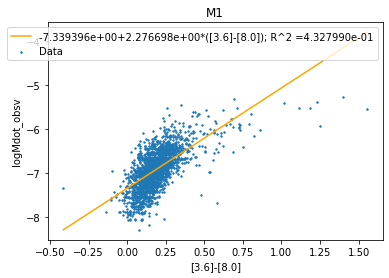

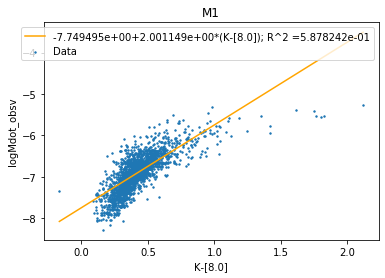


 Fit: logMdot= 3.270072212136549 *x+ -18.382895749054175


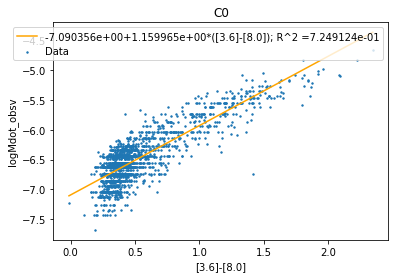

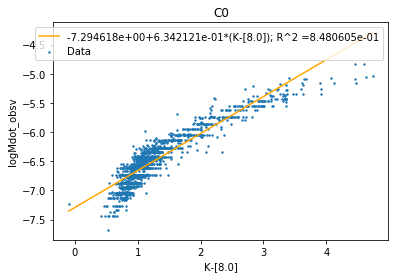


 Fit: logMdot= 2.191931543203469 *x+ -14.78990591480484


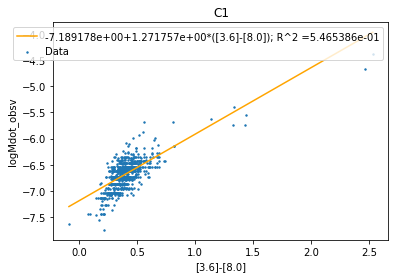

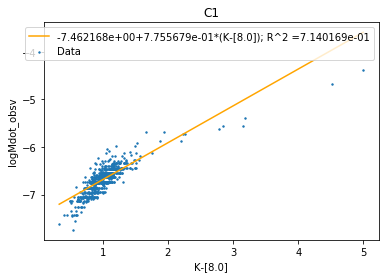

In [22]:
Directory = 'Single_Parameter_Fits/log(L/M)'
full_parameter_analysis (M0_logCL, np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(L/M)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logCL, np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(L/M)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logCL, np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(L/M)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logCL, np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(L/M)', plot_label='C1', save_fig = 1, save_folder=Directory)

Potential energy has residuals in the core mass-luminosity relation that should be removed from all star types. We need to subtract that fit from the PE fit, and redo the analysis. Temperature has residuals that should be removed in the basic parameters (M, L, P).

In [23]:
def PE_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    Correction_betas = plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)')
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*logCL)
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    print('\n Corrected Fit: logMdot=', Betas[1],'*log(M/R)+',Correction_betas[1],'log(L/M)+',Betas[0]-Correction_betas[0])
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label = 'Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    fit_label = str(Betas[1])[:6]+'*log(M/R)+'+str(Correction_betas[1])[:6]+'log(L/M)+'+str(Betas[0]-Correction_betas[0])[:6]+'; R^2 ='+ str(chisqfit_returns[1])[0:6]
    plot.plot(fit_x,fit_y,color='orange',label = fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    plot.title(plot_label)
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(M/R)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)


 Initial Fit: logMdot= -2.0140052683974288 *x+ -11.157663910225905


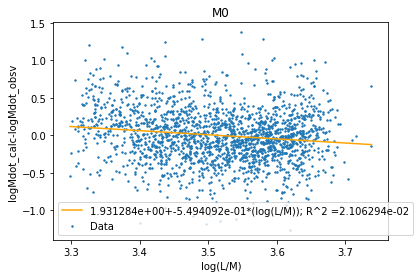


 Corrected Fit: logMdot= -2.3998607562502046 *log(M/R)+ -0.5494092355497041 log(L/M)+ -13.928451308231795


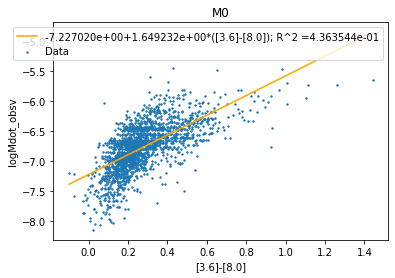

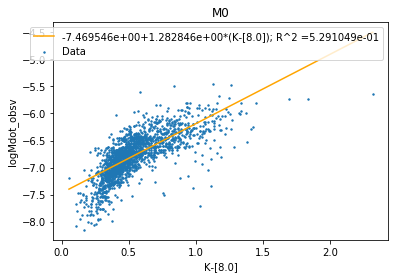




 Initial Fit: logMdot= -2.445318885514026 *x+ -12.33832559829561


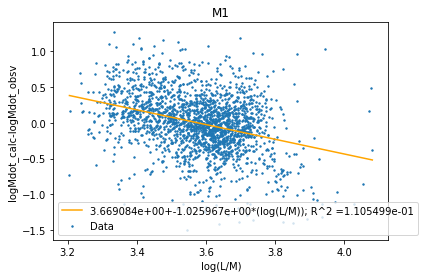


 Corrected Fit: logMdot= -3.525579425166432 *log(M/R)+ -1.0259672270924303 log(L/M)+ -18.408914329716815


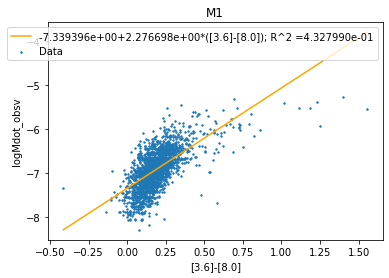

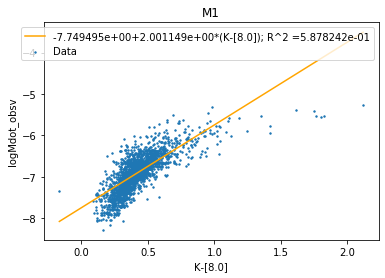




 Initial Fit: logMdot= -2.9550717214226516 *x+ -13.142535968446216


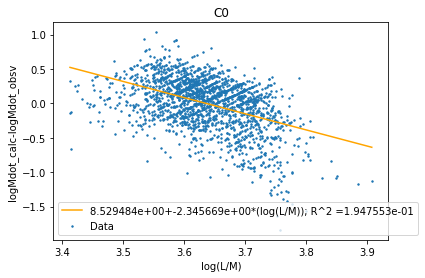


 Corrected Fit: logMdot= -3.587093367119431 *log(M/R)+ -2.345668663635828 log(L/M)+ -23.094410067532145


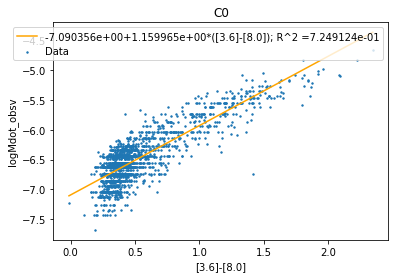

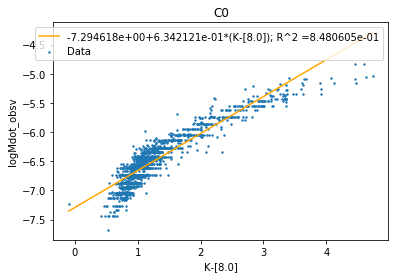




 Initial Fit: logMdot= -1.4027187481992487 *x+ -9.901832968377517


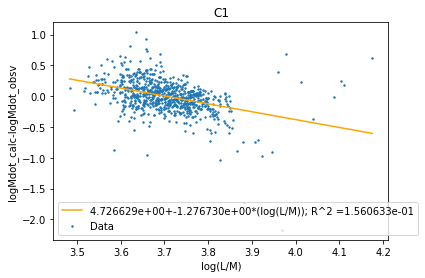


 Corrected Fit: logMdot= -2.146740012330038 *log(M/R)+ -1.2767299356837787 log(L/M)+ -16.339977833629213


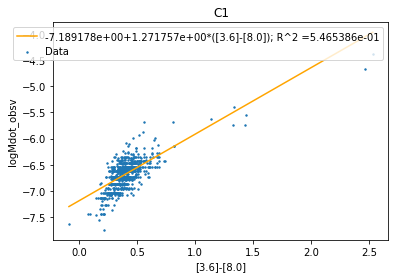

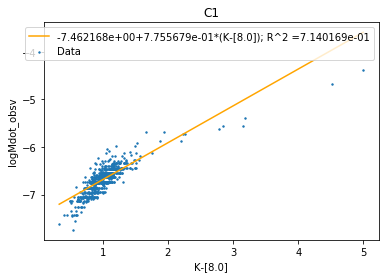

In [24]:
Directory = 'Single_Parameter_Fits/ExtendedAnalyses/log(MdivR)'
PE_minus_resid (M0_logPE, np.log10(M0StarData[MdotIndex]), M0StarData, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
PE_minus_resid (M1_logPE, np.log10(M1StarData[MdotIndex]), M1StarData, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
PE_minus_resid (C0_logPE, np.log10(C0StarData[MdotIndex]), C0StarData, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)
PE_minus_resid (C1_logPE, np.log10(C1StarData[MdotIndex]), C1StarData, stellar_data_xlabel='log(M/R)', plot_label='C1', save_fig = 1, save_folder=Directory)

In [25]:
def T_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, fed_index, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    if fed_index == RIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(R)')
    elif fed_index == LIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(L)')
    elif fed_index == PIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(P)')
    elif fed_index == MIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(M)')
    
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*np.log10(full_stellar_data[fed_index]))
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    if fed_index == RIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(R)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(R)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == LIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(L)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(L)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == PIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(P)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(P)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == MIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(M)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(M)+'+str(Betas[0]-Correction_betas[0])[:6]
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label='Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    plot.plot(fit_x,fit_y,color='orange',label=fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    plot.title(plot_label)
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(L/R^2)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)', save_fig = 1, save_folder=Directory)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    #print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label, save_fig = 1, save_folder=Directory)


 Initial Fit: logMdot= -4.983880459427999 *x+ -11.0039258595151


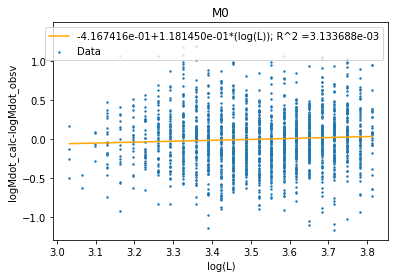


 Corrected Fit: logMdot= -4.77502757700363 *log(L/R^2)+ 0.11814500972800238 log(L)+ -10.410001956086424


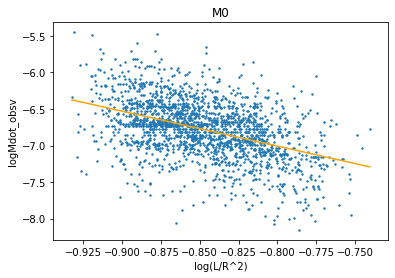

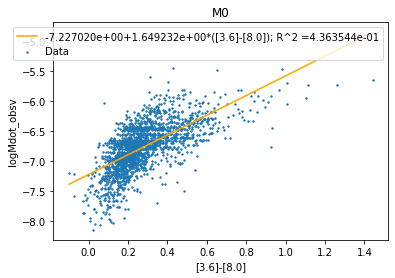

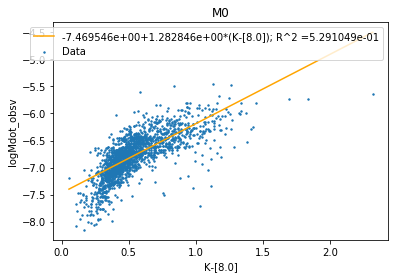

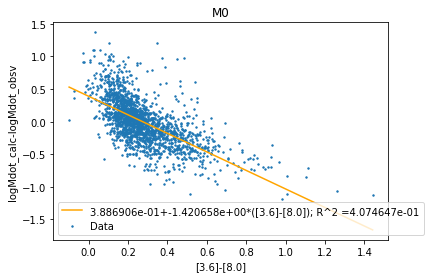

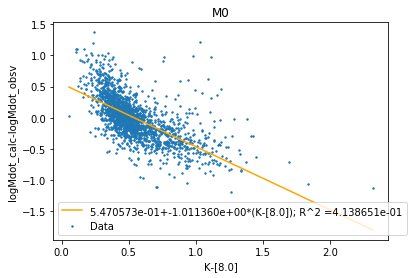


 Initial Fit: logMdot= -5.967940554038217 *x+ -12.131301347385936


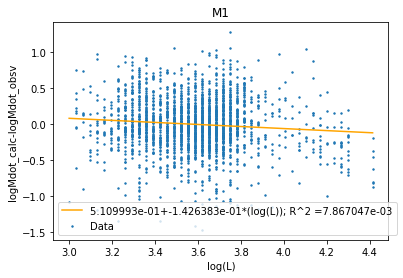


 Corrected Fit: logMdot= -6.483817392977325 *log(L/R^2)+ -0.14263832877793303 log(L)+ -13.094312184348478


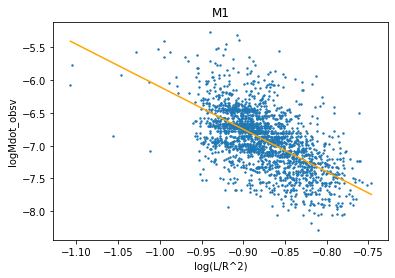

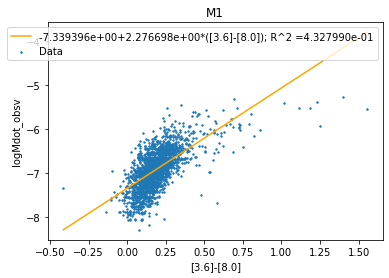

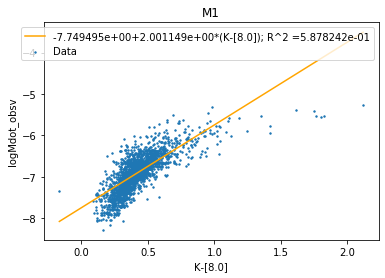

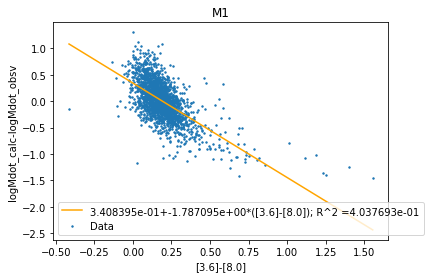

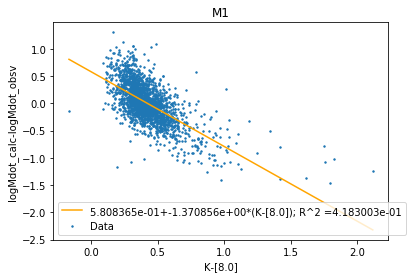


 Initial Fit: logMdot= -7.158316954479842 *x+ -13.88384379076598


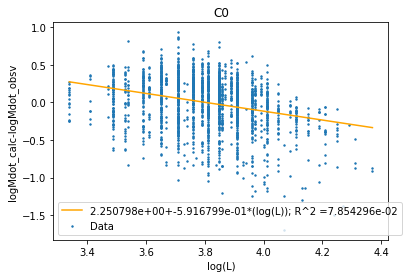


 Corrected Fit: logMdot= -6.694538696108928 *log(L/R^2)+ -0.5916799124243175 log(L)+ -15.655735237407391


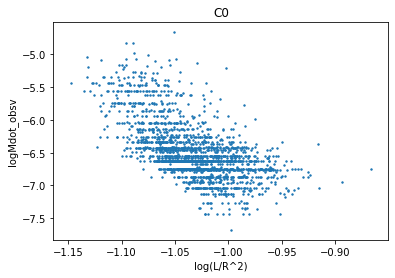

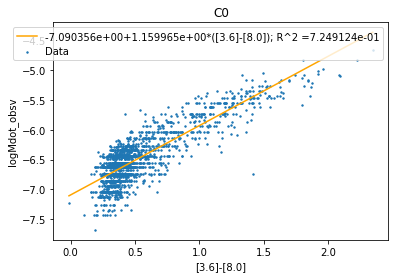

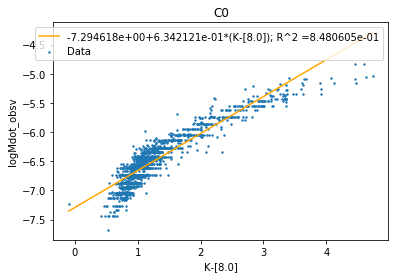

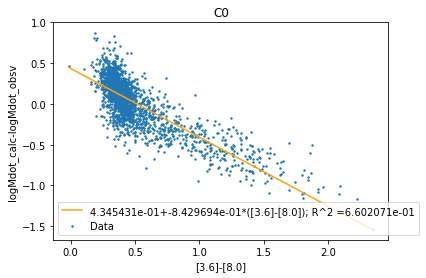

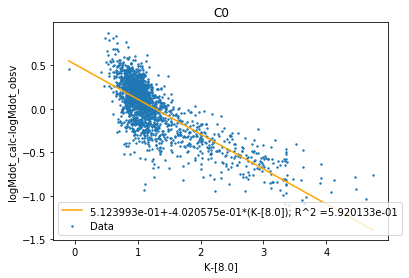


 Initial Fit: logMdot= -3.227095083374283 *x+ -10.109928487163657


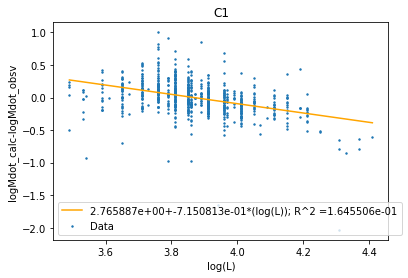


 Corrected Fit: logMdot= -3.304139672746577 *log(L/R^2)+ -0.7150813397993049 log(L)+ -12.957820420656017


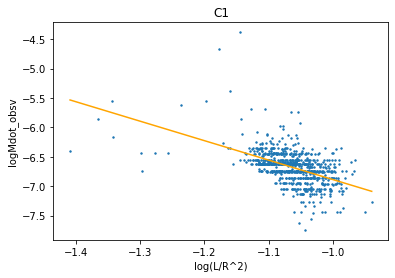

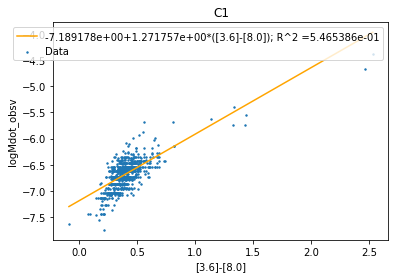

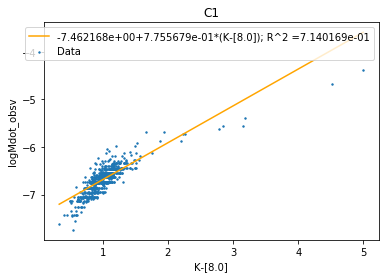

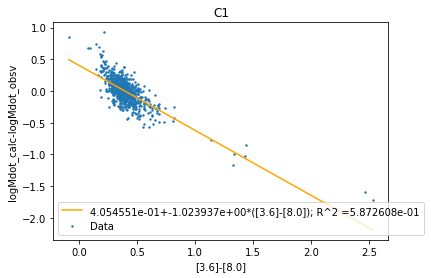

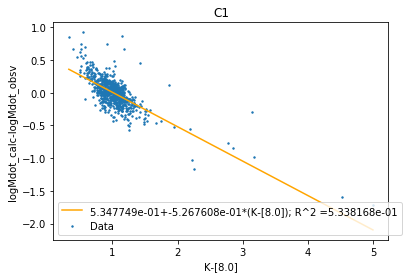

In [26]:
Directory = 'Single_Parameter_Fits/ExtendedAnalyses/log(LdivR^2)/subtract_logL'
T_minus_resid (M0_logLP, np.log10(M0StarData[MdotIndex]), M0StarData, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, np.log10(M1StarData[MdotIndex]), M1StarData, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, np.log10(C0StarData[MdotIndex]), C0StarData, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C1_logLP, np.log10(C1StarData[MdotIndex]), C1StarData, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')


 Initial Fit: logMdot= -4.983880459427999 *x+ -11.0039258595151


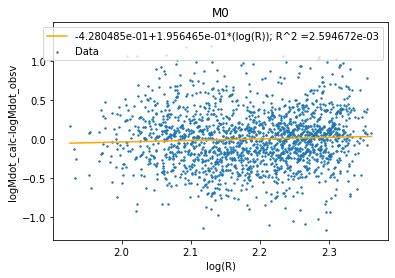


 Corrected Fit: logMdot= -4.71312846679842 *log(L/R^2)+ 0.19564650152663907 log(R)+ -10.346182474141504


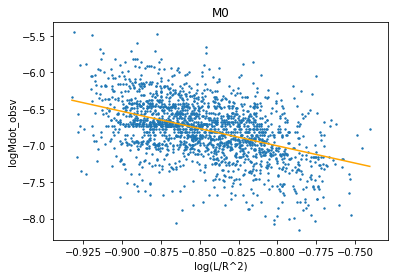

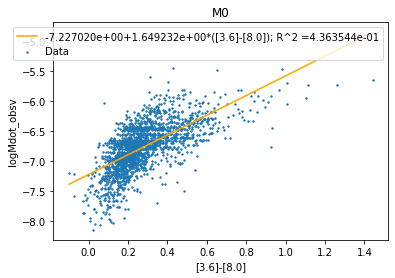

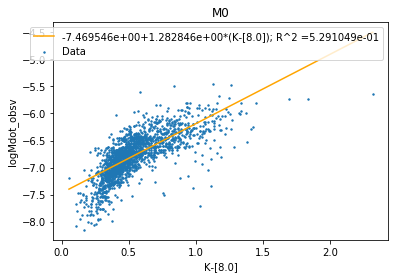

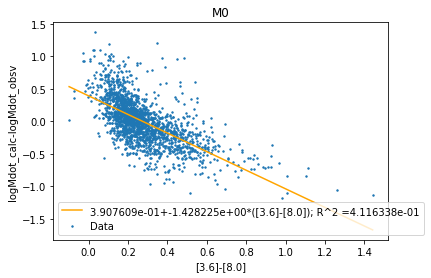

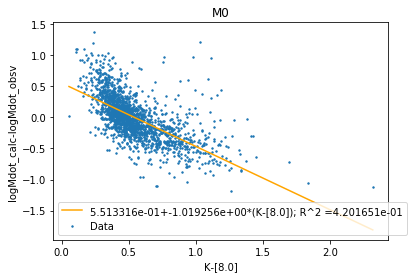


 Initial Fit: logMdot= -5.967940554038217 *x+ -12.131301347385936


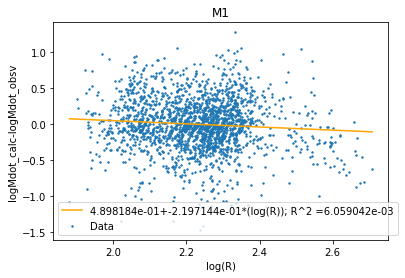


 Corrected Fit: logMdot= -6.47511577575116 *log(L/R^2)+ -0.21971438037944932 log(R)+ -13.065506902188545


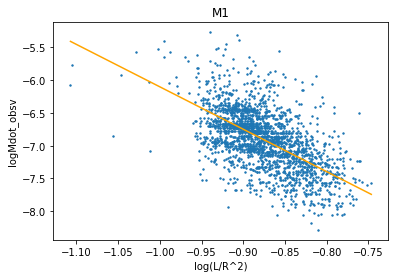

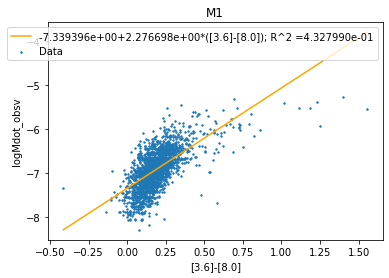

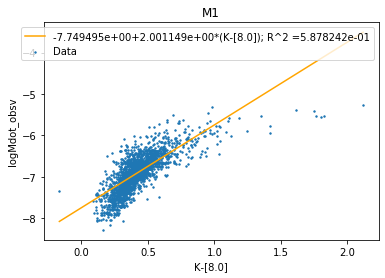

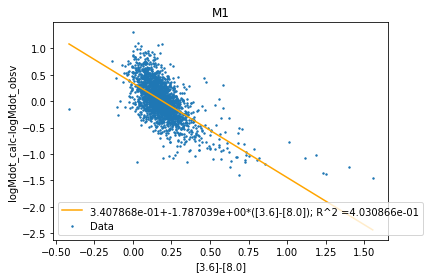

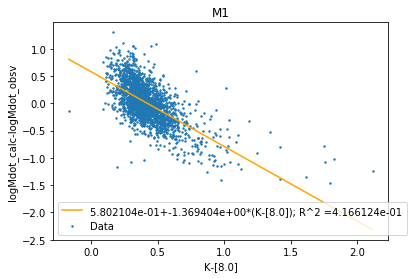


 Initial Fit: logMdot= -7.158316954479842 *x+ -13.88384379076598


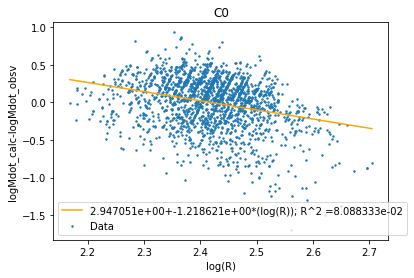


 Corrected Fit: logMdot= -7.290029737460221 *log(L/R^2)+ -1.2186207985467052 log(R)+ -16.966903746593637


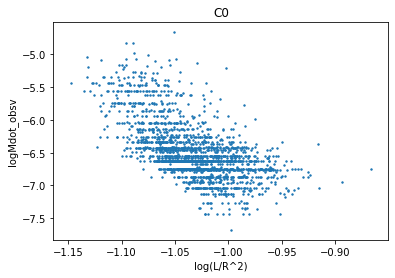

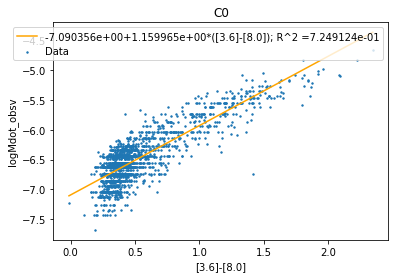

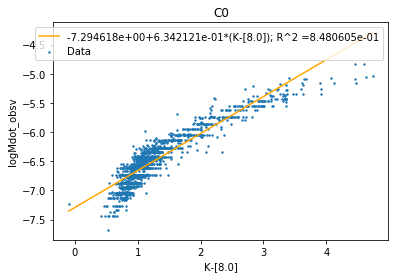

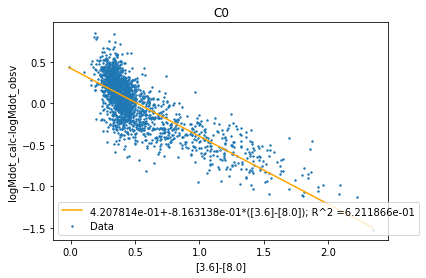

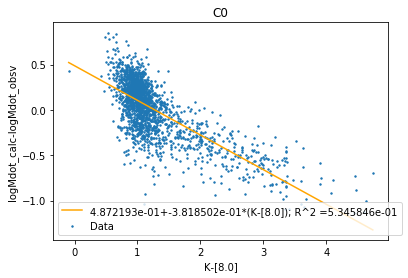


 Initial Fit: logMdot= -3.227095083374283 *x+ -10.109928487163657


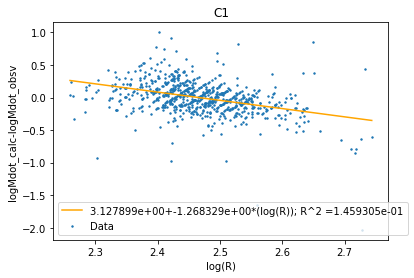


 Corrected Fit: logMdot= -3.9295861885487615 *log(L/R^2)+ -1.2683293455892946 log(R)+ -13.985543950281158


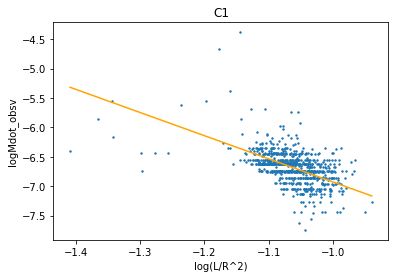

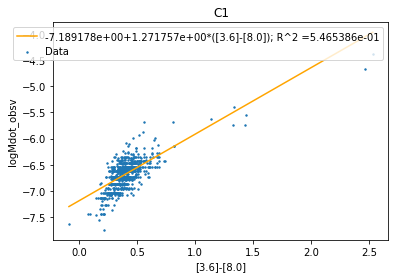

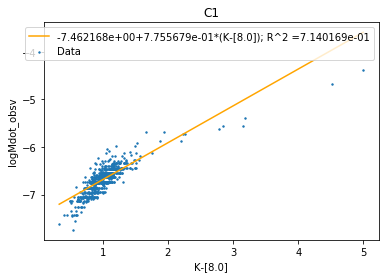

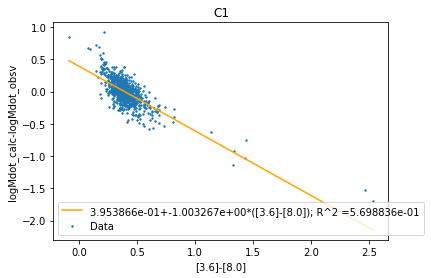

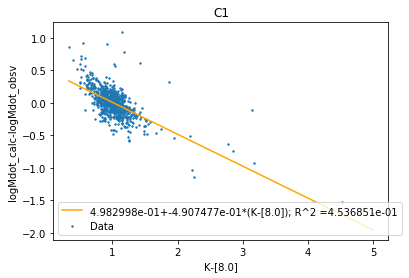

In [27]:
Directory = 'Single_Parameter_Fits/ExtendedAnalyses/log(LdivR^2)/subtract_logR'
T_minus_resid (M0_logLP, np.log10(M0StarData[MdotIndex]), M0StarData, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, np.log10(M1StarData[MdotIndex]), M1StarData, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, np.log10(C0StarData[MdotIndex]), C0StarData, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C1_logLP, np.log10(C1StarData[MdotIndex]), C1StarData, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')


 Initial Fit: logMdot= -4.983880459427999 *x+ -11.0039258595151


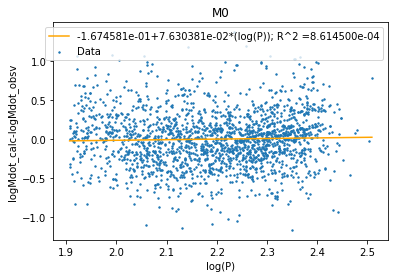


 Corrected Fit: logMdot= -4.730816071647097 *log(L/R^2)+ 0.07630380720493547 log(P)+ -10.621778220431022


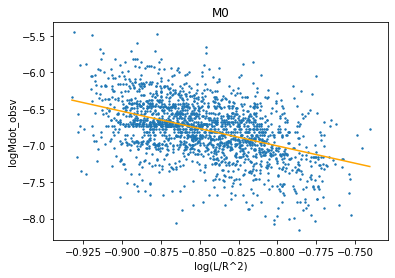

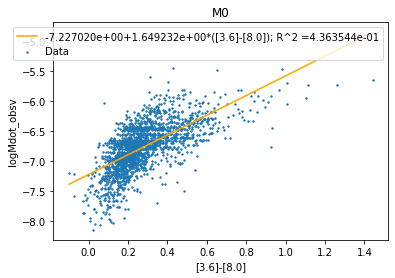

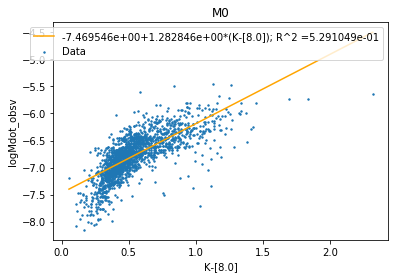

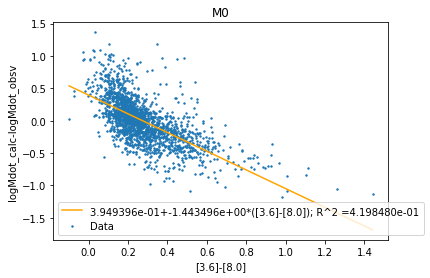

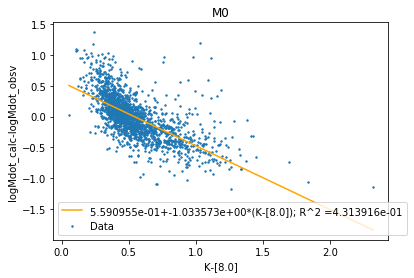


 Initial Fit: logMdot= -5.967940554038217 *x+ -12.131301347385936


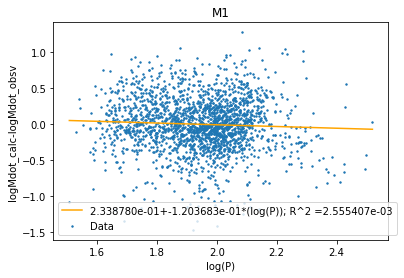


 Corrected Fit: logMdot= -6.356780788804198 *log(L/R^2)+ -0.12036831599430393 log(P)+ -12.705881400783767


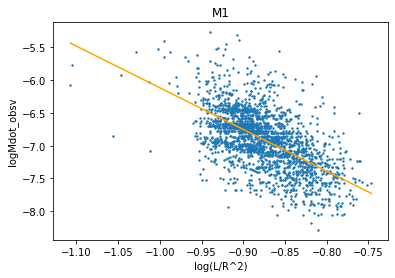

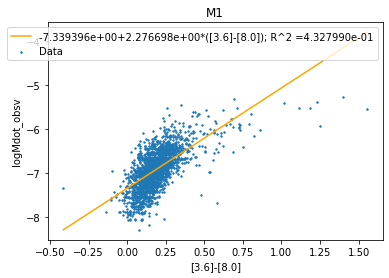

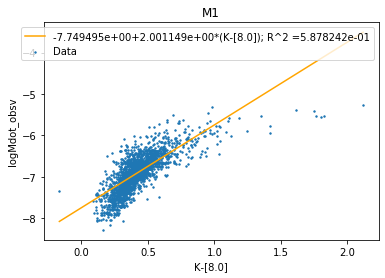

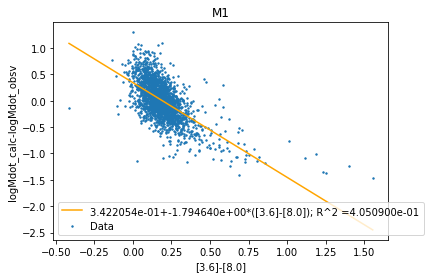

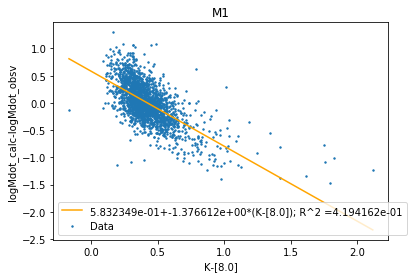


 Initial Fit: logMdot= -7.158316954479842 *x+ -13.88384379076598


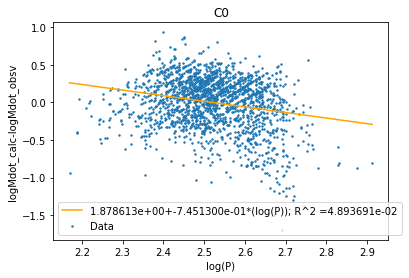


 Corrected Fit: logMdot= -8.460826849729528 *log(L/R^2)+ -0.7451299836847585 log(P)+ -17.107453359491007


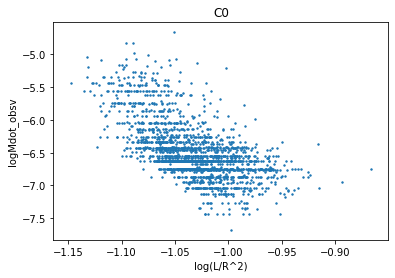

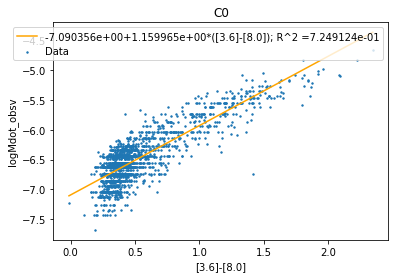

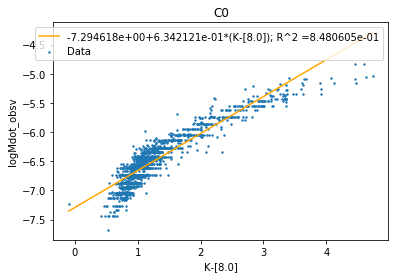

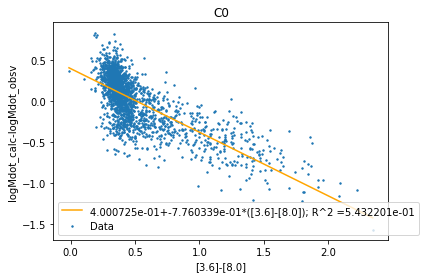

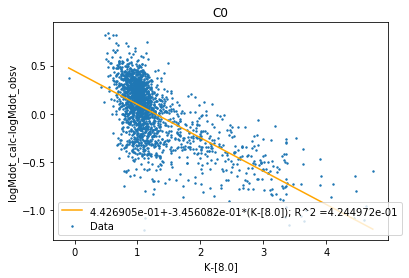


 Initial Fit: logMdot= -3.227095083374283 *x+ -10.109928487163657


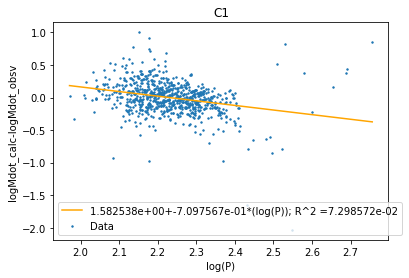


 Corrected Fit: logMdot= -4.324096053609681 *log(L/R^2)+ -0.7097566506412961 log(P)+ -12.860091427603587


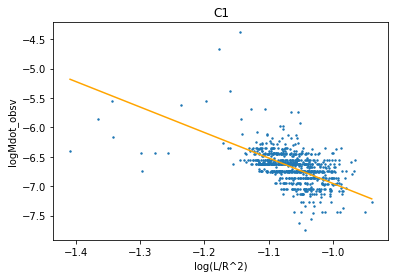

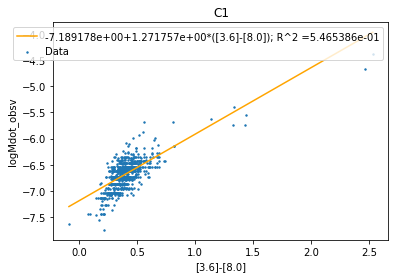

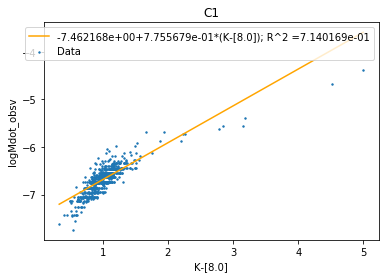

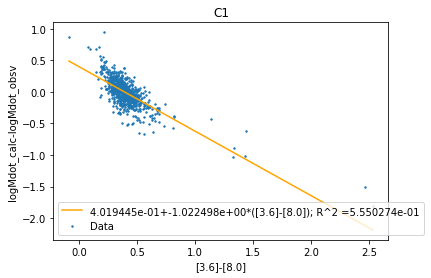

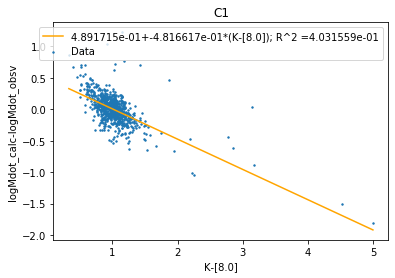

In [28]:
Directory = 'Single_Parameter_Fits/ExtendedAnalyses/log(LdivR^2)/subtract_logP'
T_minus_resid (M0_logLP, np.log10(M0StarData[MdotIndex]), M0StarData, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, np.log10(M1StarData[MdotIndex]), M1StarData, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, np.log10(C0StarData[MdotIndex]), C0StarData, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C1_logLP, np.log10(C1StarData[MdotIndex]), C1StarData, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')


 Initial Fit: logMdot= -4.983880459427999 *x+ -11.0039258595151


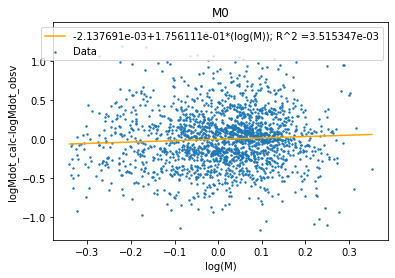


 Corrected Fit: logMdot= -5.099012004935461 *log(L/R^2)+ 0.17561112176875465 log(M)+ -11.09946106961785


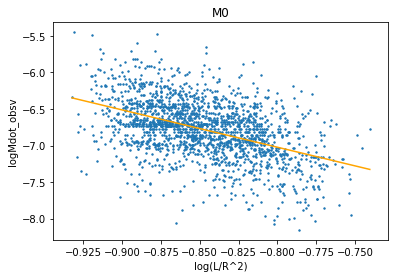

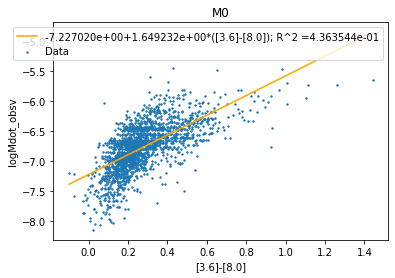

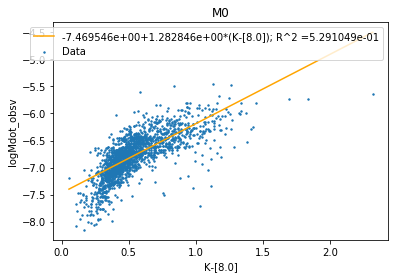

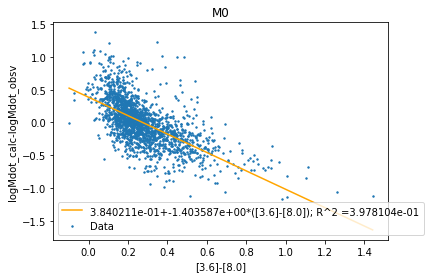

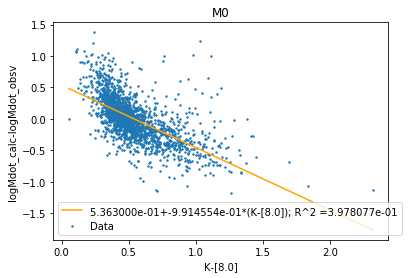


 Initial Fit: logMdot= -5.967940554038217 *x+ -12.131301347385936


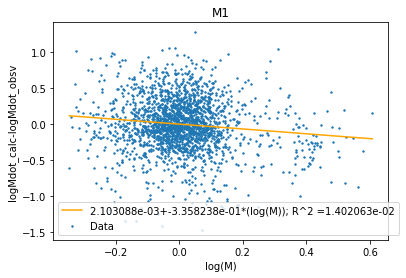


 Corrected Fit: logMdot= -6.218361823710216 *log(L/R^2)+ -0.3358238099682197 log(M)+ -12.352823682084592


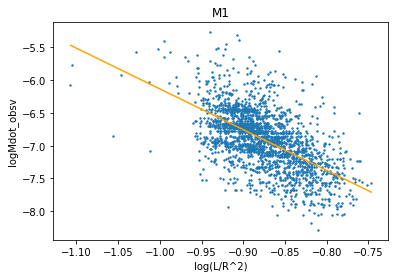

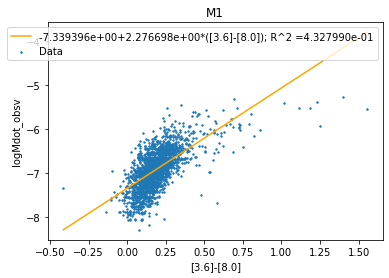

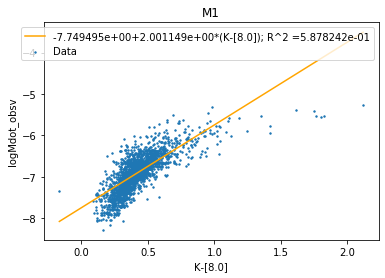

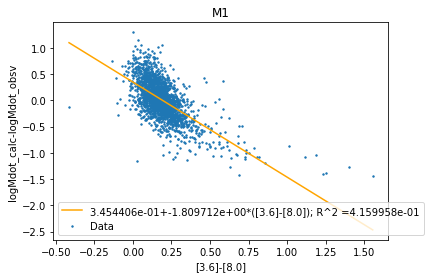

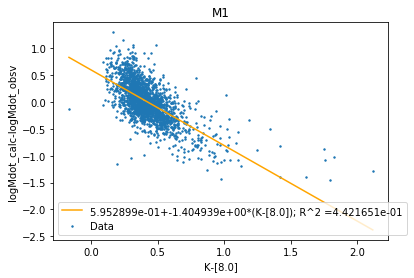


 Initial Fit: logMdot= -7.158316954479842 *x+ -13.88384379076598


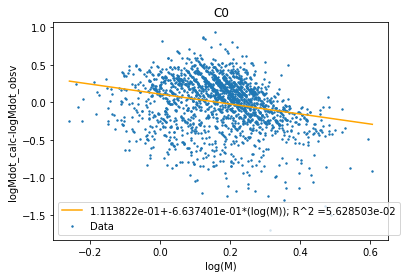


 Corrected Fit: logMdot= -5.931438307824591 *log(L/R^2)+ -0.663740060489546 log(M)+ -12.728327888216363


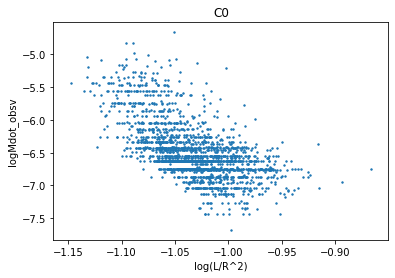

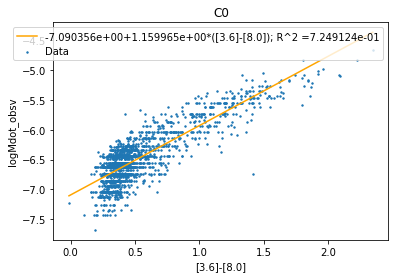

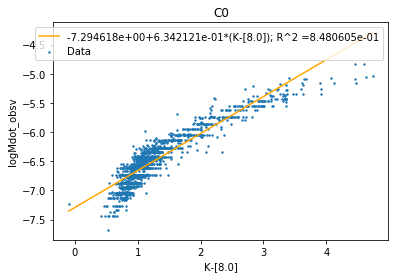

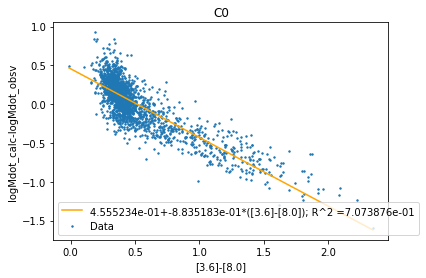

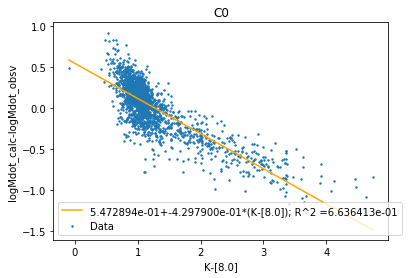


 Initial Fit: logMdot= -3.227095083374283 *x+ -10.109928487163657


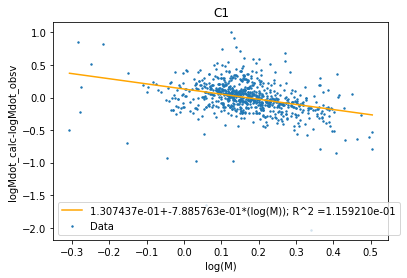


 Corrected Fit: logMdot= -2.2185994635179993 *log(L/R^2)+ -0.7885762640188443 log(M)+ -9.167250532059816


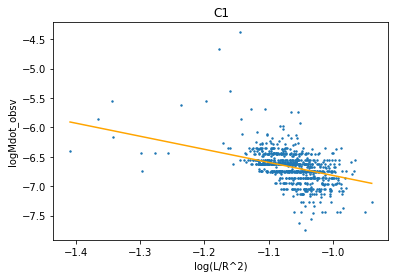

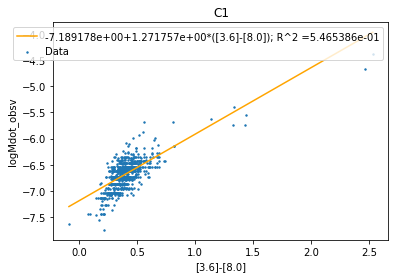

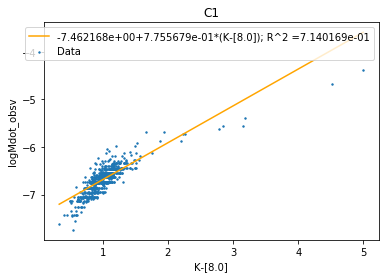

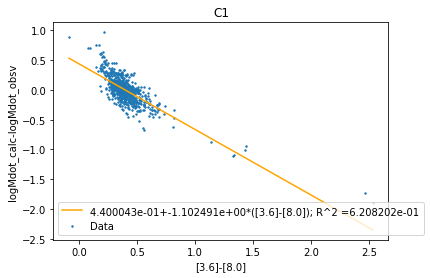

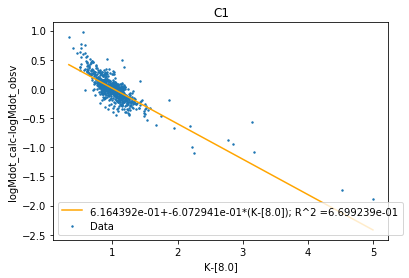

In [29]:
Directory = 'Single_Parameter_Fits/ExtendedAnalyses/log(LdivR^2)/subtract_logM'
T_minus_resid (M0_logLP, np.log10(M0StarData[MdotIndex]), M0StarData, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, np.log10(M1StarData[MdotIndex]), M1StarData, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, np.log10(C0StarData[MdotIndex]), C0StarData, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C1_logLP, np.log10(C1StarData[MdotIndex]), C1StarData, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')

Removing residuals in from our Temperature proxy results in no significant improvement. We should take the initial fit to be complete.